# 01 – Models, calibration and threshold

DBA5106 Project 2 – Bank Marketing (term deposit subscription).

**Question.** Which customers should the bank call? A wasted call is cheap, a missed subscriber is expensive,
so the evaluation loss is a business cost, not the misclassification rate.

**Plan (Lecture 11 brief).**
1. Data: drop `duration` (leakage), recode `pdays`, stratified 60 / 20 / 20 split.
2. Evaluation loss: `COST_FP` per wasted call, `COST_FN` per missed subscriber (placeholders, set in `src/bank.py`).
3. Four models – a glass-box and a black-box, each trained with L2 loss and with log loss:
   ridge regression vs logistic regression; gradient boosting with squared error vs log loss.
   Each is tuned separately (5-fold CV on train only, so the validation set is not overfitted).
4. Compare by validation AUC.
5. Check calibration; fix with Platt or isotonic scaling fitted on out-of-fold train predictions.
6. Pick the threshold that minimises the business cost on validation; report once on test.
7. Save the boosting model for Tree SHAP (`02_shap.ipynb`).

In [1]:
import sys, time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "bank.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, brier_score_loss, log_loss, make_scorer,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

import bank
from bank import COST_FN, COST_FP, SEED, business_loss

FIG, MODELS, RESULTS = ROOT / "figures", ROOT / "models", ROOT / "results"
for d in (FIG, MODELS, RESULTS):
    d.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data

UCI Bank Marketing, `bank-additional-full.csv` (Moro, Cortez & Rita, 2014): 41,188 calls, May 2008 – Nov 2010.
`duration` is dropped because it is only known after the call. `pdays = 999` means "never contacted", so it is
replaced by a `contacted_before` flag. "unknown" stays as its own category.

In [2]:
raw = bank.load_raw()
df = bank.clean(raw)
print("raw:", raw.shape, "-> cleaned:", df.shape)

train, val, test = bank.split(df)
X_train, y_train = bank.xy(train)
X_val, y_val = bank.xy(val)
X_test, y_test = bank.xy(test)

pd.DataFrame({"rows": [len(train), len(val), len(test)],
              "subscription rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"])

raw: (41188, 21) -> cleaned: (41188, 20)


,rows,subscription rate
train,24712,0.1127
validation,8238,0.1126
test,8238,0.1126


**Why not a time split?** Rows are in date order. Splitting by row order gives very different subscription rates
(and very different economic conditions) in each part. We use the stratified split for the main results and show
this drift as a limitation.

In [3]:
drift = pd.DataFrame(
    [[len(p), p["y"].mean(), p["euribor3m"].mean(), p["nr.employed"].mean()]
     for p in bank.time_split(df)],
    columns=["rows", "subscription rate", "mean euribor3m", "mean nr.employed"],
    index=["first 60% (train)", "next 20% (val)", "last 20% (test)"])
drift.to_csv(RESULTS / "time_split_drift.csv")
drift

,rows,subscription rate,mean euribor3m,mean nr.employed
first 60% (train),24712,0.0481,4.9046,5215.5109
next 20% (val),8238,0.1107,2.3621,5134.0329
last 20% (test),8238,0.3083,1.0307,5054.6257


## 2. Evaluation loss and baselines

Average cost per customer = (`COST_FP` × wasted calls + `COST_FN` × missed subscribers) / customers.

If the probabilities are calibrated, calling a customer is worth it when
p × `COST_FN` > (1 − p) × `COST_FP`, i.e. p > `COST_FP` / (`COST_FP` + `COST_FN`).

In [4]:
t_theory = COST_FP / (COST_FP + COST_FN)
print(f"COST_FP = {COST_FP}, COST_FN = {COST_FN}  ->  cost-optimal threshold if calibrated = {t_theory:.4f}")

def baseline_costs(y):
    return {"call everyone": business_loss(y, np.ones(len(y)), 0.5),
            "call no one": business_loss(y, np.zeros(len(y)), 0.5)}

baselines = pd.DataFrame({"validation": baseline_costs(y_val), "test": baseline_costs(y_test)})
baselines

COST_FP = 5, COST_FN = 50  ->  cost-optimal threshold if calibrated = 0.0909


,validation,test
call everyone,4.4368,4.4368
call no one,5.6324,5.6324


## 3. Four models, each tuned separately

| | glass-box | black-box |
|---|---|---|
| L2 (squared error) on the 0/1 label | Ridge regression | Gradient boosting, `loss="squared_error"` |
| Surrogate: log loss (deviance) | Logistic regression (L2 penalty) | Gradient boosting, `loss="log_loss"` |

Hyperparameters are chosen by 5-fold cross-validated AUC **on the training set only**. The validation set is kept
for comparing the four tuned models, checking calibration and choosing the threshold, so it is not used
over and over for tuning (overfitting in validation, Lecture 11). Preprocessing sits inside the pipeline, so it is
refitted in every fold.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
auc_of_prediction = make_scorer(roc_auc_score)   # regressors: AUC of the continuous prediction

def make_pipe(model, X=X_train):
    return Pipeline([("prep", bank.make_preprocessor(X)), ("model", model)])

def scores(pipe, X):
    """Continuous score: P(yes) for classifiers, raw prediction for L2 regressors."""
    est = pipe.named_steps["model"]
    return est.predict_proba(pipe[:-1].transform(X))[:, 1] if hasattr(est, "predict_proba") else pipe.predict(X)

GB_GRID = {"model__n_estimators": [100, 300],
           "model__max_depth": [2, 3, 4],
           "model__learning_rate": [0.05, 0.1]}

specs = {
    "Ridge (L2)": dict(box="glass-box", loss="squared error (L2)",
                       model=Ridge(), grid={"model__alpha": np.logspace(-2, 4, 13)},
                       scoring=auc_of_prediction),
    "Logistic (log loss)": dict(box="glass-box", loss="log loss",
                                model=LogisticRegression(max_iter=5000),
                                grid={"model__C": np.logspace(-4, 2, 13)}, scoring="roc_auc"),
    "GB (L2)": dict(box="black-box", loss="squared error (L2)",
                    model=GradientBoostingRegressor(loss="squared_error", subsample=0.8, random_state=SEED),
                    grid=GB_GRID, scoring=auc_of_prediction),
    "GB (log loss)": dict(box="black-box", loss="log loss",
                          model=GradientBoostingClassifier(loss="log_loss", subsample=0.8, random_state=SEED),
                          grid=GB_GRID, scoring="roc_auc"),
}

fitted, rows = {}, []
for name, s in specs.items():
    t0 = time.time()
    search = GridSearchCV(make_pipe(s["model"]), s["grid"], scoring=s["scoring"], cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    rows.append({"model": name, "type": s["box"], "training loss": s["loss"],
                 "best hyperparameters": best, "CV AUC (train)": search.best_score_})
    print(f"{name:20s} CV AUC {search.best_score_:.4f}  {best}  ({time.time() - t0:.0f}s)")

Ridge (L2)           CV AUC 0.7813  {'alpha': np.float64(100.0)}  (7s)


Logistic (log loss)  CV AUC 0.7837  {'C': np.float64(0.1)}  (2s)


GB (L2)              CV AUC 0.7910  {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300}  (76s)


GB (log loss)        CV AUC 0.7917  {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300}  (80s)


## 4. Compare by validation AUC

In [6]:
val_scores = {n: scores(m, X_val) for n, m in fitted.items()}
summary = pd.DataFrame(rows).set_index("model")
summary["train AUC"] = [roc_auc_score(y_train, scores(fitted[n], X_train)) for n in summary.index]
summary["validation AUC"] = [roc_auc_score(y_val, val_scores[n]) for n in summary.index]
summary.to_csv(RESULTS / "model_comparison.csv")
summary[["type", "training loss", "best hyperparameters", "CV AUC (train)", "train AUC", "validation AUC"]]

,type,training loss,best hyperparameters,CV AUC (train),train AUC,validation AUC
model,,,,,,
Ridge (L2),glass-box,squared error (L2),{'alpha': 100.0},0.7813,0.7874,0.7994
Logistic (log loss),glass-box,log loss,{'C': 0.1},0.7837,0.7895,0.8010
GB (L2),black-box,squared error (L2),"{'learning_rate': 0.05, 'max_depth': 4, 'n_est...",0.7910,0.8242,0.8044
GB (log loss),black-box,log loss,"{'learning_rate': 0.05, 'max_depth': 4, 'n_est...",0.7917,0.8228,0.8060


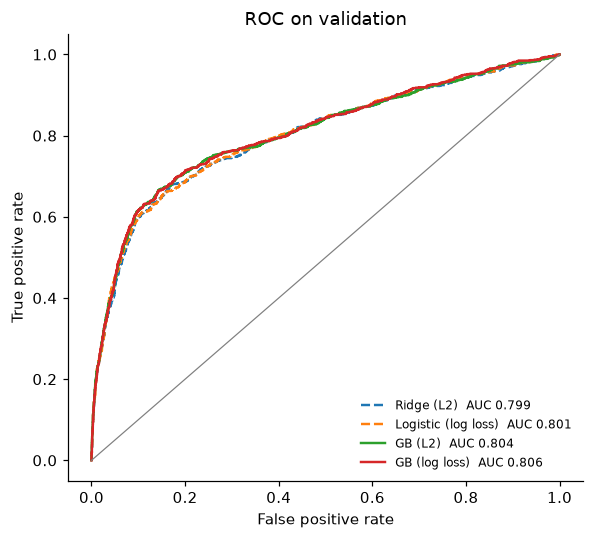

Best glass-box: Logistic (log loss) | best black-box: GB (log loss) | selected model: GB (log loss)


In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for n, s in val_scores.items():
    fpr, tpr, _ = roc_curve(y_val, s)
    ax.plot(fpr, tpr, lw=1.6, ls="-" if "GB" in n else "--", label=f"{n}  AUC {roc_auc_score(y_val, s):.3f}")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC on validation")
ax.legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "roc_validation.png", bbox_inches="tight")
plt.show()

best_name = summary["validation AUC"].idxmax()
best_glass = summary.loc[summary["type"] == "glass-box", "validation AUC"].idxmax()
best_black = summary.loc[summary["type"] == "black-box", "validation AUC"].idxmax()
print("Best glass-box:", best_glass, "| best black-box:", best_black, "| selected model:", best_name)

## 5. Calibration

AUC only depends on the ranking. The threshold rule p > `COST_FP` / (`COST_FP` + `COST_FN`) needs probabilities that
are right on average. The two L2 models do not even output probabilities (ridge can predict below 0 or above 1).

Fix: fit a calibration map from score to probability on **out-of-fold predictions on the training set**
(5-fold `cross_val_predict` with the tuned hyperparameters), then apply it to validation and test.
Two maps: Platt (logistic on the score) and isotonic (monotone step function). For each model we keep the one with
the lower validation Brier score.

In [8]:
EPS = 1e-6

def oof_scores(pipe):
    method = "predict_proba" if hasattr(pipe.named_steps["model"], "predict_proba") else "predict"
    s = cross_val_predict(clone(pipe), X_train, y_train, cv=cv, method=method, n_jobs=-1)
    return s[:, 1] if s.ndim == 2 else s

class Platt:
    def fit(self, s, y):
        self.lr = LogisticRegression(C=1e6).fit(np.c_[s], y); return self
    def predict(self, s):
        return self.lr.predict_proba(np.c_[s])[:, 1]

class Raw:   # "no calibration": clip the score into [0, 1]
    def fit(self, s, y): return self
    def predict(self, s): return np.clip(s, EPS, 1 - EPS)

calibrators, cal_rows = {}, []
for n, pipe in fitted.items():
    s_oof = oof_scores(pipe)
    maps = {"none (clipped)": Raw(),
            "Platt": Platt().fit(s_oof, y_train),
            "isotonic": IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(s_oof, y_train)}
    for m_name, cal in maps.items():
        p = np.clip(cal.predict(val_scores[n]), EPS, 1 - EPS)
        cal_rows.append({"model": n, "calibration": m_name, "Brier": brier_score_loss(y_val, p),
                         "log loss": log_loss(y_val, p), "mean p": p.mean(), "val rate": y_val.mean()})
    calibrators[n] = maps

cal_table = pd.DataFrame(cal_rows)
cal_table.to_csv(RESULTS / "calibration_validation.csv", index=False)
chosen_cal = cal_table.loc[cal_table.groupby("model")["Brier"].idxmin()].set_index("model")["calibration"]
print("Chosen calibration (lowest validation Brier):", chosen_cal.to_dict())
cal_table.pivot(index="model", columns="calibration", values="Brier")

Chosen calibration (lowest validation Brier): {'GB (L2)': 'none (clipped)', 'GB (log loss)': 'isotonic', 'Logistic (log loss)': 'isotonic', 'Ridge (L2)': 'isotonic'}


calibration,Platt,isotonic,none (clipped)
model,,,
GB (L2),0.0772,0.0759,0.0759
GB (log loss),0.0777,0.0757,0.0760
Logistic (log loss),0.0779,0.0766,0.0767
Ridge (L2),0.0779,0.0769,0.0772


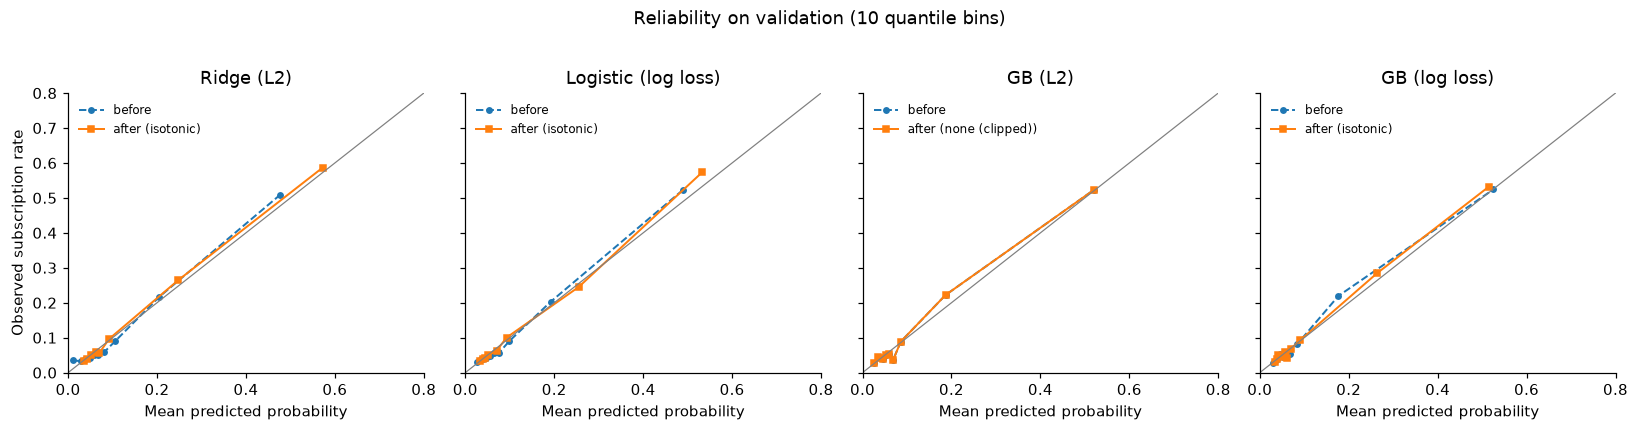

In [9]:
val_prob = {n: np.clip(calibrators[n][chosen_cal[n]].predict(val_scores[n]), EPS, 1 - EPS) for n in fitted}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, n in zip(axes, fitted):
    raw_p = np.clip(val_scores[n], EPS, 1 - EPS)
    for p, lab, st in [(raw_p, "before", "o--"), (val_prob[n], f"after ({chosen_cal[n]})", "s-")]:
        frac, mean_p = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
        ax.plot(mean_p, frac, st, ms=3.5, lw=1.3, label=lab)
    ax.plot([0, 0.8], [0, 0.8], color="grey", lw=0.8)
    ax.set(title=n, xlabel="Mean predicted probability", xlim=(0, 0.8), ylim=(0, 0.8))
    ax.legend(fontsize=8, frameon=False, loc="upper left")
axes[0].set_ylabel("Observed subscription rate")
fig.suptitle("Reliability on validation (10 quantile bins)", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "calibration_validation.png", bbox_inches="tight")
plt.show()

## 6. Threshold that minimises the business cost

For each model, scan thresholds on the calibrated validation probabilities and keep the one with the lowest
average cost. Compare with the theoretical threshold `COST_FP` / (`COST_FP` + `COST_FN`) and with the baselines.

In [10]:
grid = np.round(np.arange(0, 1.0001, 0.0025), 4)

def best_threshold(y, p, cost_fp=COST_FP, cost_fn=COST_FN):
    costs = np.array([business_loss(y, p, t, cost_fp, cost_fn) for t in grid])
    i = costs.argmin()
    return grid[i], costs[i], costs

best_baseline_val = baselines["validation"].min()
thr_rows, thr_curves = [], {}
for n in fitted:
    t_best, c_best, curve = best_threshold(y_val, val_prob[n])
    thr_curves[n] = curve
    thr_rows.append({"model": n, "validation AUC": summary.loc[n, "validation AUC"],
                     "chosen threshold": t_best, "val cost at chosen t": c_best,
                     "val cost at theory t": business_loss(y_val, val_prob[n], t_theory),
                     "val cost at t = 0.5": business_loss(y_val, val_prob[n], 0.5),
                     "saving vs best baseline": 1 - c_best / best_baseline_val})
thr_table = pd.DataFrame(thr_rows).set_index("model")
thr_table.to_csv(RESULTS / "threshold_validation.csv")
thr_table

,validation AUC,chosen threshold,val cost at chosen t,val cost at theory t,val cost at t = 0.5,saving vs best baseline
model,,,,,,
Ridge (L2),0.7994,0.0725,2.6299,2.6305,4.3396,0.4073
Logistic (log loss),0.8010,0.0900,2.6566,2.6566,4.3512,0.4012
GB (L2),0.8044,0.1050,2.5188,2.5589,4.2395,0.4323
GB (log loss),0.8060,0.0825,2.5000,2.5479,4.2577,0.4365


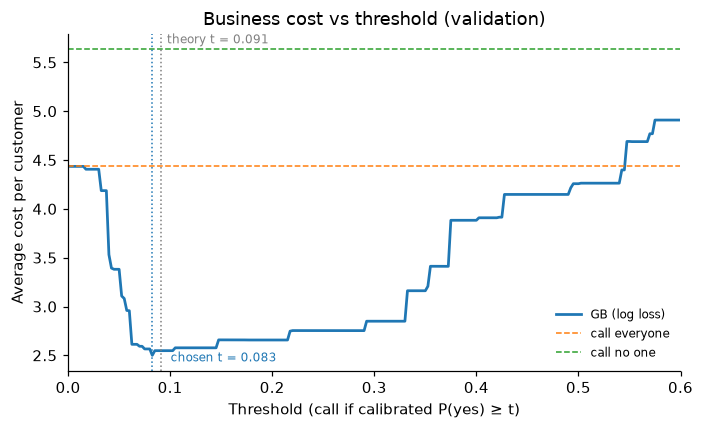

In [11]:
final_threshold = thr_table.loc[best_name, "chosen threshold"]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(grid, thr_curves[best_name], color="C0", lw=1.8, label=best_name)
ax.axhline(baselines.loc["call everyone", "validation"], color="C1", ls="--", lw=1, label="call everyone")
ax.axhline(baselines.loc["call no one", "validation"], color="C2", ls="--", lw=1, label="call no one")
ax.axvline(final_threshold, color="C0", ls=":", lw=1)
ax.axvline(t_theory, color="grey", ls=":", lw=1)
ax.annotate(f"chosen t = {final_threshold:.3f}", (final_threshold, thr_curves[best_name].min()),
            xytext=(12, -4), textcoords="offset points", fontsize=8, color="C0")
ax.annotate(f"theory t = {t_theory:.3f}", (t_theory, baselines['validation'].max()),
            xytext=(4, 4), textcoords="offset points", fontsize=8, color="grey")
ax.set(xlim=(0, 0.6), xlabel="Threshold (call if calibrated P(yes) ≥ t)",
       ylabel="Average cost per customer", title="Business cost vs threshold (validation)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "cost_vs_threshold.png", bbox_inches="tight")
plt.show()

**Accuracy is the wrong yardstick.** With 11% "yes", predicting "no" for everyone already looks accurate.

In [12]:
def decision_stats(y, p, t, label):
    call = p >= t
    return {"rule": label, "accuracy": accuracy_score(y, call), "share called": call.mean(),
            "subscribers reached": (call & (y == 1)).sum() / (y == 1).sum(),
            "avg cost": business_loss(y, p, t)}

p_best = val_prob[best_name]
acc_table = pd.DataFrame([
    decision_stats(y_val, np.zeros(len(y_val)), 0.5, "call no one"),
    decision_stats(y_val, np.ones(len(y_val)), 0.5, "call everyone"),
    decision_stats(y_val, p_best, 0.5, f"{best_name}, t = 0.5"),
    decision_stats(y_val, p_best, final_threshold, f"{best_name}, t = {final_threshold:.3f}"),
]).set_index("rule")
acc_table.to_csv(RESULTS / "accuracy_vs_cost_validation.csv")
acc_table

,accuracy,share called,subscribers reached,avg cost
rule,,,,
call no one,0.8874,0.0000,0.0000,5.6324
call everyone,0.1126,1.0000,1.0000,4.4368
"GB (log loss), t = 0.5",0.9012,0.0442,0.2575,4.2577
"GB (log loss), t = 0.083",0.7895,0.2588,0.7144,2.5000


## 7. Final result on the test set (used once)

Selected model, its calibration map and the threshold are all fixed from train / validation.
The other three models are shown for reference only; they did not influence any choice.

In [13]:
test_rows = []
for n in fitted:
    s = scores(fitted[n], X_test)
    p = np.clip(calibrators[n][chosen_cal[n]].predict(s), EPS, 1 - EPS)
    t = thr_table.loc[n, "chosen threshold"]
    call = p >= t
    test_rows.append({"model": n, "selected": n == best_name, "test AUC": roc_auc_score(y_test, s),
                      "test Brier": brier_score_loss(y_test, p), "threshold": t,
                      "test avg cost": business_loss(y_test, p, t), "share called": call.mean(),
                      "subscribers reached": (call & (y_test == 1)).sum() / (y_test == 1).sum()})
test_table = pd.DataFrame(test_rows).set_index("model")
test_table["saving vs best baseline"] = 1 - test_table["test avg cost"] / baselines["test"].min()
test_table.to_csv(RESULTS / "test_results.csv")
display(baselines)
test_table

,validation,test
call everyone,4.4368,4.4368
call no one,5.6324,5.6324


,selected,test AUC,test Brier,threshold,test avg cost,share called,subscribers reached,saving vs best baseline
model,,,,,,,,
Ridge (L2),False,0.7975,0.0780,0.0725,2.7021,0.2899,0.7069,0.3910
Logistic (log loss),False,0.8008,0.0776,0.0900,2.6833,0.2541,0.6810,0.3952
GB (L2),False,0.8089,0.0760,0.1050,2.5971,0.2021,0.6530,0.4146
GB (log loss),True,0.8096,0.0761,0.0825,2.5825,0.2566,0.6994,0.4179


In [14]:
p_test = np.clip(calibrators[best_name][chosen_cal[best_name]].predict(scores(fitted[best_name], X_test)), EPS, 1 - EPS)
call = p_test >= final_threshold
cm = pd.DataFrame([[((~call) & (y_test == 0)).sum(), (call & (y_test == 0)).sum()],
                   [((~call) & (y_test == 1)).sum(), (call & (y_test == 1)).sum()]],
                  index=["actual: no", "actual: yes"], columns=["not called", "called"])
print(f"{best_name} on test, threshold {final_threshold:.3f}")
cm

GB (log loss) on test, threshold 0.083


,not called,called
actual: no,5845,1465
actual: yes,279,649


## 8. Sensitivity to the cost numbers

`COST_FP` and `COST_FN` are placeholders. Only their ratio matters for the decision, so here is the selected model
under different ratios (validation, `COST_FP` fixed).

In [15]:
sens = []
for ratio in [2, 5, 10, 20, 50]:
    c_fn = ratio * COST_FP
    t_b, c_b, _ = best_threshold(y_val, p_best, COST_FP, c_fn)
    base = min(business_loss(y_val, np.ones(len(y_val)), .5, COST_FP, c_fn),
               business_loss(y_val, np.zeros(len(y_val)), .5, COST_FP, c_fn))
    sens.append({"COST_FN / COST_FP": ratio, "theory t": COST_FP / (COST_FP + c_fn), "chosen t": t_b,
                 "share called": (p_best >= t_b).mean(), "model cost": c_b, "best baseline cost": base,
                 "saving vs best baseline": 1 - c_b / base})
sens = pd.DataFrame(sens).set_index("COST_FN / COST_FP")
sens.to_csv(RESULTS / "cost_sensitivity_validation.csv")
sens

,theory t,chosen t,share called,model cost,best baseline cost,saving vs best baseline
COST_FN / COST_FP,,,,,,
2,0.3333,0.3325,0.1040,0.8309,1.1265,0.2624
5,0.1667,0.1750,0.1487,1.5313,2.8162,0.4563
10,0.0909,0.0825,0.2588,2.5000,4.4368,0.4365
20,0.0476,0.0550,0.5328,3.9743,4.4368,0.1042
50,0.0196,0.0025,0.9996,4.4349,4.4368,0.0004


## 9. Limitation: time drift and the economic indicators

The five economic indicators change over time, so in a random split they partly tell the model *when* the call was
made. Two checks with the selected model and its tuned hyperparameters:
(a) drop the five indicators; (b) train on the first 60% of calls in time and evaluate on the later 20% / 20%.

In [16]:
def refit_auc(X_tr, y_tr, evals):
    pipe = make_pipe(clone(fitted[best_name].named_steps["model"]), X_tr).fit(X_tr, y_tr)
    return [roc_auc_score(y_e, scores(pipe, X_e)) for X_e, y_e in evals]

no_macro = lambda X: X.drop(columns=bank.MACRO_COLS)
auc_no_macro = refit_auc(no_macro(X_train), y_train, [(no_macro(X_val), y_val)])[0]

t_tr, t_va, t_te = (bank.xy(p) for p in bank.time_split(df))
auc_time = refit_auc(*t_tr, [t_va, t_te])

limits = pd.DataFrame({"AUC": [summary.loc[best_name, "validation AUC"], auc_no_macro, auc_time[0], auc_time[1]]},
                      index=["random split, all features (validation)",
                             "random split, no economic indicators (validation)",
                             "time split: next 20% (validation)", "time split: last 20% (test)"])
limits.to_csv(RESULTS / "limitations_auc.csv")
limits

,AUC
"random split, all features (validation)",0.8060
"random split, no economic indicators (validation)",0.7820
time split: next 20% (validation),0.4652
time split: last 20% (test),0.5417


### 9b. Why is the time-split AUC at or below 0.5?

It is not a bug: an AUC below 0.5 means the model ranks later customers in the *wrong* order, i.e. it learned
patterns that reverse over time. The rows are in date order, so the first 60% (train) are roughly May–Nov 2008,
the next 20% roughly Nov 2008 – May 2009 and the last 20% roughly May 2009 – Nov 2010. Three checks:

1. **What each period looks like** – subscription rate, months present, range of the economic indicators,
   and how many customers had a previous campaign.
2. **Direction of single features within each period** – AUC of the raw feature
   (> 0.5: higher value goes with more "yes").
3. **Which feature groups transfer** – refit on the first 60% with only one group of features, for the selected
   boosting model and for the tuned logistic regression.

In [17]:
periods = dict(zip(["train (first 60%)", "next 20%", "last 20%"], bank.time_split(df)))
profile = pd.DataFrame({
    n: {"rows": len(d), "subscription rate": d["y"].mean(),
        "months present": ", ".join(m for m in ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
                                    if m in set(d["month"])),
        "euribor3m range": f"{d['euribor3m'].min():.2f} – {d['euribor3m'].max():.2f}",
        "emp.var.rate range": f"{d['emp.var.rate'].min():.1f} – {d['emp.var.rate'].max():.1f}",
        "distinct macro combinations": len(d[bank.MACRO_COLS].drop_duplicates()),
        "share with previous contact": (d["previous"] > 0).mean(),
        "share previous outcome = success": (d["poutcome"] == "success").mean()}
    for n, d in periods.items()})
profile.to_csv(RESULTS / "time_split_profile.csv")
profile

,train (first 60%),next 20%,last 20%
rows,24712,8238,8238
subscription rate,0.0481,0.1107,0.3083
months present,"may, jun, jul, aug, oct, nov","mar, apr, may, nov, dec","mar, apr, may, jun, jul, aug, sep, oct, nov, dec"
euribor3m range,4.19 – 5.04,1.30 – 4.19,0.63 – 1.30
emp.var.rate range,-0.1 – 1.4,-1.8 – -0.1,-3.4 – -1.1
distinct macro combinations,59,62,256
share with previous contact,0.0053,0.2604,0.4067
share previous outcome = success,0.0002,0.0197,0.1463


In [18]:
single = ["age", "campaign", "previous"] + bank.MACRO_COLS
direction = pd.DataFrame({n: [roc_auc_score(d["y"], d[c]) for c in single] for n, d in periods.items()}, index=single)
direction.to_csv(RESULTS / "time_split_feature_direction.csv")
direction

,train (first 60%),next 20%,last 20%
age,0.4754,0.4683,0.5394
campaign,0.5001,0.4736,0.4396
previous,0.4999,0.4670,0.5965
emp.var.rate,0.5295,0.3897,0.4872
cons.price.idx,0.4427,0.4044,0.5737
cons.conf.idx,0.4641,0.3083,0.6573
euribor3m,0.5507,0.4647,0.2997
nr.employed,0.5462,0.3897,0.2778


In [19]:
all_cols = [c for c in X_train.columns]
no_macro_cols = [c for c in all_cols if c not in bank.MACRO_COLS]
feature_groups = {
    "all features": all_cols,
    "economic indicators only": bank.MACRO_COLS,
    "month only": ["month"],
    "without economic indicators": no_macro_cols,
    "without economic indicators, month, weekday": [c for c in no_macro_cols if c not in ("month", "day_of_week")],
}
(p_tr, _, _) = periods.values()
group_rows = []
for model_name in [best_name, "Logistic (log loss)"]:
    for g, cols in feature_groups.items():
        X_tr = p_tr[cols]
        pipe = make_pipe(clone(fitted[model_name].named_steps["model"]), X_tr).fit(X_tr, p_tr["y"])
        for n, d in list(periods.items())[1:]:
            group_rows.append({"model": model_name, "features": g, "period": n,
                               "AUC": roc_auc_score(d["y"], scores(pipe, d[cols]))})
groups_auc = pd.DataFrame(group_rows).pivot_table(index="features", columns=["model", "period"], values="AUC")
groups_auc = groups_auc.reindex(list(feature_groups))
groups_auc.to_csv(RESULTS / "time_split_feature_groups_auc.csv")
groups_auc

model                                       GB (log loss)           \
period                                           last 20% next 20%   
features                                                             
all features                                       0.5417   0.4652   
economic indicators only                           0.6612   0.3899   
month only                                         0.6885   0.4575   
without economic indicators                        0.6345   0.4361   
without economic indicators, month, weekday        0.5701   0.5197   

model                                       Logistic (log loss)           
period                                                 last 20% next 20%  
features                                                                  
all features                                             0.4713   0.4890  
economic indicators only                                 0.3478   0.4646  
month only                                               0.6901   0.6485  
without economic indicators                              0.7023   0.6152  
without economic indicators, month, weekday              0.6574   0.6041

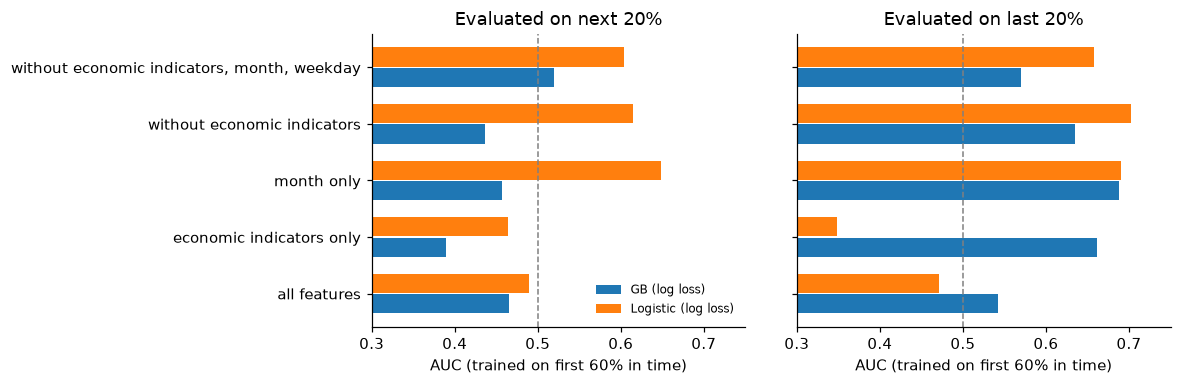

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, period in zip(axes, list(periods)[1:]):
    sub = groups_auc.xs(period, axis=1, level="period")
    y_pos = np.arange(len(sub))
    for k, (m, off) in enumerate([(best_name, -0.18), ("Logistic (log loss)", 0.18)]):
        ax.barh(y_pos + off, sub[m], height=0.34, color=f"C{k}", label=m)
    ax.axvline(0.5, color="grey", lw=1, ls="--")
    ax.set(yticks=y_pos, yticklabels=sub.index, xlim=(0.3, 0.75), xlabel="AUC (trained on first 60% in time)",
           title=f"Evaluated on {period}")
    ax.invert_yaxis()
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "time_split_feature_groups.png", bbox_inches="tight")
plt.show()

**Reading the three tables.**

1. **The economic indicators act as date stamps, and their effect reverses.** In the training period they take
   only a handful of values, and their ranges do not overlap with later periods at all. Within 2008 they only mark
   *which week* a call was made; the single-feature AUCs show the direction flipping between periods
   (e.g. `euribor3m` and `nr.employed`). A model on the economic indicators alone can score **below 0.5** on later data
   (boosting on the next 20%, logistic regression on the last 20%), and trees cannot extrapolate beyond the
   training range.
2. **The best months never appear in training.** March, April, September and December are absent from the first 60%
   and later have the highest subscription rates.
3. **The strongest real signal did not exist yet.** In 2008 almost nobody had been contacted in a previous
   campaign, so the model never saw `poutcome = success`, one of the best predictors later on.

What still transfers is the stable customer / contact information: **logistic regression without the economic
indicators** keeps a clearly-better-than-random AUC on both later periods, while boosting – which fits the
period-specific detail more closely – does worse. So the glass-box model is the more robust one under drift.

**Implication.** The random-split AUC (≈ 0.81) is valid for calls made under similar conditions, but overstates
performance in a new economic period. In practice: retrain regularly, monitor drift, and treat the economic
indicators with care.

## 10. Save for Tree SHAP (`02_shap.ipynb`)

- `models/boosting_for_shap.joblib` – the best black-box (fitted pipeline: preprocessing + gradient boosting).
  Use `pipe[:-1].transform(X)` for the features, `pipe[:-1].get_feature_names_out()` for names, and
  `shap.TreeExplainer(pipe[-1])`.
- `models/final_model.joblib` – selected model, calibration map, threshold and costs.
- Rebuild the same train / validation / test split with `bank.split(bank.clean(bank.load_raw()))`.

In [21]:
boost = fitted[best_black]
joblib.dump(boost, MODELS / "boosting_for_shap.joblib")
joblib.dump({"name": best_name, "pipeline": fitted[best_name],
             "calibration": chosen_cal[best_name], "calibrator": calibrators[best_name][chosen_cal[best_name]],
             "threshold": final_threshold, "cost_fp": COST_FP, "cost_fn": COST_FN},
            MODELS / "final_model.joblib")
feature_names = boost[:-1].get_feature_names_out()
pd.Series(feature_names, name="feature").to_csv(MODELS / "feature_names.csv", index=False)
print("Saved:", best_black, "->", (MODELS / "boosting_for_shap.joblib").relative_to(ROOT), f"({len(feature_names)} features)")

Saved: GB (log loss) -> models/boosting_for_shap.joblib (62 features)


In [22]:
r = test_table.loc[best_name]
print("KEY NUMBERS FOR THE SLIDES")
print(f"  Costs: wasted call = {COST_FP}, missed subscriber = {COST_FN}  (placeholders)")
print(f"  Validation AUC: " + ", ".join(f"{n} {v:.3f}" for n, v in summary['validation AUC'].items()))
print(f"  Selected: {best_name}, calibration = {chosen_cal[best_name]}, threshold = {final_threshold:.3f} "
      f"(theory {t_theory:.3f})")
print(f"  Test: AUC {r['test AUC']:.3f}, avg cost {r['test avg cost']:.3f} vs best baseline "
      f"{baselines['test'].min():.3f} ({r['saving vs best baseline']:.0%} saving); "
      f"calls {r['share called']:.0%} of customers and reaches {r['subscribers reached']:.0%} of subscribers")

KEY NUMBERS FOR THE SLIDES
  Costs: wasted call = 5, missed subscriber = 50  (placeholders)
  Validation AUC: Ridge (L2) 0.799, Logistic (log loss) 0.801, GB (L2) 0.804, GB (log loss) 0.806
  Selected: GB (log loss), calibration = isotonic, threshold = 0.083 (theory 0.091)
  Test: AUC 0.810, avg cost 2.583 vs best baseline 4.437 (42% saving); calls 26% of customers and reaches 70% of subscribers
